# CIFAR-10: Does BN or a residual connection improve LeNet?
**Data → Model → Train or load → Evaluation → Visualization**.

Compare **baseline / BN / residual / BN + residual** using the same LeNet-style network.

**Before class:** set `MODE = "train"`, run once, and keep the generated `cnn_checkpoints` folder.
**During class:** use `MODE = "load"` to load weights, learning curves, and recorded results. No training is run in this mode. Checkpoints are created by your first training run; they are not bundled here.

Requires `torch`, `torchvision`, and `matplotlib`. CIFAR-10 downloads on the first run. A GPU is helpful for training. Keep the dataset cached for class. Run cells in order.

In [1]:
# Uncomment if the packages are missing; restart the kernel after installation.
# %pip install torch torchvision matplotlib

## 1. Data
CIFAR-10 contains RGB images of **10 classes**, each of size **32 × 32**.
Split the official training set into **45,000 training** and **5,000 validation** examples. Keep the **10,000 test** examples for final evaluation.

PyTorch stores image batches as **(B, C, H, W)**. Map pixel values from [0, 1] to [-1, 1]; this fixed preprocessing is separate from batch normalization.

In [2]:
import copy
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split

torch.manual_seed(0)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

batch_size = 128
# transform = transforms.Compose([
#     transforms.ToTensor(),
#     transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
# ])

mean = (0.4914, 0.4822, 0.4465)
std  = (0.2023, 0.1994, 0.2010)
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])


all_train = datasets.CIFAR10("./data", train=True, download=True, transform=transform)
test_data = datasets.CIFAR10("./data", train=False, download=True, transform=transform)
train_data, val_data = random_split(
    all_train, [45000, 5000], generator=torch.Generator().manual_seed(0)
)
classes = all_train.classes
# num_workers=0 works in notebooks on Windows, macOS, and Linux.
train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True,
                          generator=torch.Generator().manual_seed(1), num_workers=0)
val_loader = DataLoader(val_data, batch_size=batch_size, shuffle=False, num_workers=0)
test_loader = DataLoader(test_data, batch_size=batch_size, shuffle=False, num_workers=0)
print("Train / validation / test:", len(train_data), len(val_data), len(test_data))
print("Classes:", classes)

Device: cuda
Train / validation / test: 45000 5000 10000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


### View the dataset
Undo the fixed normalization only when displaying images.

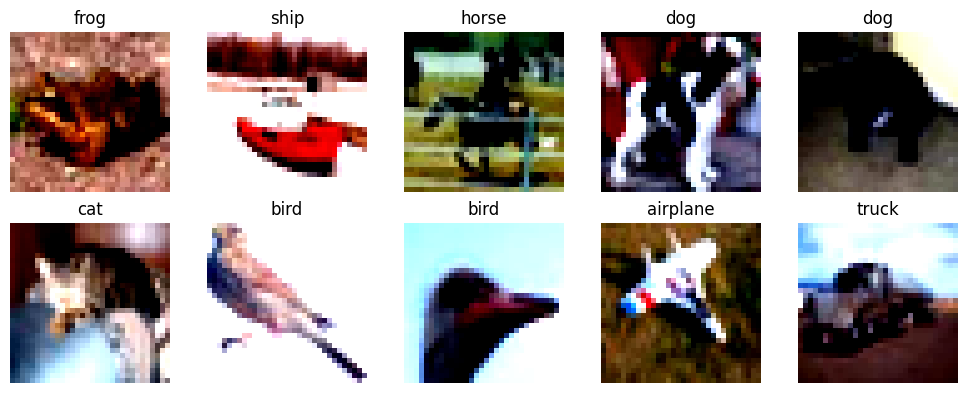

One image: (3, 32, 32)


In [3]:
def image_for_display(x):
    return (x.detach().cpu() * 0.5 + 0.5).clamp(0, 1).permute(1, 2, 0)

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for i, ax in enumerate(axes.flat):
    x, y = train_data[i]
    ax.imshow(image_for_display(x))
    ax.set_title(classes[y])
    ax.axis("off")
plt.tight_layout()
plt.show()
print("One image:", tuple(train_data[0][0].shape))

## 2. Model: four versions of one LeNet-style CNN
Use **two convolutions and three dense layers**, with channel/width schedule **6 → 16 → 120 → 84 → 10**.
Padding preserves spatial size inside each convolutional stage; pooling then reduces it. All four versions use this same schedule. This is a classroom adaptation, not the historical LeNet-5.

| Stage | Output (excluding batch) |
|---|---|
| Input | 3 × 32 × 32 |
| Conv 5 × 5, padding 2 → activation → pool | 6 × 16 × 16 |
| Conv 5 × 5, padding 2 → activation → pool | 16 × 8 × 8 |
| Flatten | 1024 |
| Linear → ReLU | 120 |
| Linear → ReLU | 84 |
| Linear | 10 logits |

Each stage computes one of:

| Variant | Before pooling |
|---|---|
| Baseline | $\mathrm{ReLU}(K*X+b)$ |
| BN | $\mathrm{ReLU}(\mathrm{BN}(K*X+b))$ |
| Residual | $\mathrm{ReLU}(K*X+b+S(X))$ |
| BN + residual | $\mathrm{ReLU}(\mathrm{BN}(K*X+b)+S(X))$ |

$S$ is a **1 × 1 projection** because the channel counts change (3 → 6 and 6 → 16). Add before pooling, when height and width match. These simple one-convolution residual stages illustrate the idea; a standard ResNet basic block uses two convolutions.

In [4]:
class ConvStage(nn.Module):
    def __init__(self, in_channels, out_channels, use_bn=False, use_residual=False):
        super().__init__()
        # Retain the same convolution parameters in all variants.
        self.conv = nn.Conv2d(in_channels, out_channels, 5, padding=2)
        self.bn = nn.BatchNorm2d(out_channels) if use_bn else nn.Identity()
        self.shortcut = (nn.Conv2d(in_channels, out_channels, 1, bias=False)
                         if use_residual else None)
        self.pool = nn.MaxPool2d(2)

    def forward(self, x):
        f = self.bn(self.conv(x))
        if self.shortcut is not None:
            f = f + self.shortcut(x)
        return self.pool(torch.relu(f))


class LeNet5(nn.Module):
    def __init__(self, use_bn=False, use_residual=False):
        super().__init__()
        self.stage1 = ConvStage(3, 6, use_bn, use_residual)
        self.stage2 = ConvStage(6, 16, use_bn, use_residual)
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(16 * 8 * 8, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x):
        x = self.stage2(self.stage1(x))
        x = self.flatten(x)
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        return self.fc3(x)

variants = {
    "Baseline": (False, False),
    "BN": (True, False),
    "Residual": (False, True),
    "BN + residual": (True, True),
}
criterion = nn.CrossEntropyLoss()

# Copy common initial weights explicitly; merely resetting the seed is insufficient
# because added layers consume random numbers during initialization.
def make_models(seed):
    torch.manual_seed(seed)
    reference = LeNet5().state_dict()
    models = {}
    for name, flags in variants.items():
        torch.manual_seed(seed + 1)
        net = LeNet5(*flags)
        state = net.state_dict()
        for key, value in reference.items():
            state[key] = value.clone()
        net.load_state_dict(state)
        models[name] = net
    return models

models = make_models(0)
for name, net in models.items():
    with torch.no_grad():
        net.eval()
        output = net(torch.zeros(2, 3, 32, 32))
    print(f"{name:16s}: output={tuple(output.shape)}, "
          f"parameters={sum(p.numel() for p in net.parameters()):,}")

Baseline        : output=(2, 10), parameters=136,886
BN              : output=(2, 10), parameters=136,930
Residual        : output=(2, 10), parameters=137,000
BN + residual   : output=(2, 10), parameters=137,044


### Track one residual stage
Both branches must have identical shapes at addition. BN preserves shape.

In [5]:
net = models["BN + residual"].eval()
x = torch.stack([train_data[i][0] for i in range(4)])
with torch.no_grad():
    for stage in [net.stage1, net.stage2]:
        f = stage.bn(stage.conv(x))
        s = stage.shortcut(x)
        h = torch.relu(f + s)
        p = stage.pool(h)
        print("X:", tuple(x.shape), "\t\t F(X):", tuple(f.shape), " \t\t S(X):", tuple(s.shape))
        print("After addition + ReLU:", tuple(h.shape), "\t\t  After pooling:", tuple(p.shape))
        x = p

X: (4, 3, 32, 32) 		 F(X): (4, 6, 32, 32)  		 S(X): (4, 6, 32, 32)
After addition + ReLU: (4, 6, 32, 32) 		  After pooling: (4, 6, 16, 16)
X: (4, 6, 16, 16) 		 F(X): (4, 16, 16, 16)  		 S(X): (4, 16, 16, 16)
After addition + ReLU: (4, 16, 16, 16) 		  After pooling: (4, 16, 8, 8)


### Batch normalization: two channels
BN computes a separate mean and variance for each channel over the batch and spatial positions. The learned scale and shift start at 1 and 0. The small epsilon term makes the normalized patterns below approximately, rather than exactly, equal.

`train()` uses mini-batch statistics and updates running estimates. `eval()` uses the stored estimates. Both BN parameters **and running statistics** are saved in `state_dict()`.

Before BN
  channel means: tensor([1.1000e+02, 1.1000e-01])
  channel stds:  tensor([22.3607,  0.0224])
After BN
  channel means: tensor([1.4901e-07, 2.0862e-07])
  channel stds:  tensor([1.0000, 0.9901])


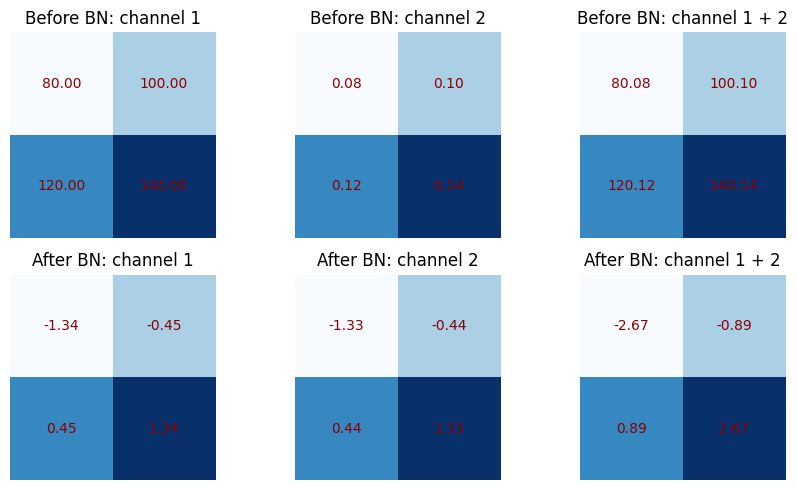

In [6]:
pattern = torch.tensor([-1.0, 0.0, 1.0, 2.0]).reshape(1, 1, 2, 2)
A_demo = torch.cat([100 + 20 * pattern, 0.10 + 0.02 * pattern], dim=1)
bn_demo = nn.BatchNorm2d(2)  # One gamma and beta per channel.
bn_demo.train()
normalized = bn_demo(A_demo)
combine = nn.Conv2d(2, 1, kernel_size=1, bias=False)
with torch.no_grad():
    combine.weight.fill_(1.0)
    before = combine(A_demo)
    after = combine(normalized)
for name, tensor in [("Before BN", A_demo), ("After BN", normalized)]:
    print(name)
    print("  channel means:", tensor.mean(dim=(0, 2, 3)).detach())
    print("  channel stds: ", tensor.std(dim=(0, 2, 3), unbiased=False).detach())
fig, axes = plt.subplots(2, 3, figsize=(9, 5))
for row, (values, output, label) in enumerate([
    (A_demo, before, "Before BN"), (normalized, after, "After BN")
]):
    for col, matrix in enumerate([values[0, 0], values[0, 1], output[0, 0]]):
        matrix = matrix.detach()
        axes[row, col].imshow(matrix, cmap="Blues")
        for i in range(2):
            for j in range(2):
                axes[row, col].text(j, i, f"{matrix[i,j]:.2f}", ha="center", va="center", color="darkred")
        axes[row, col].set_title(label + ": " + ["channel 1", "channel 2", "channel 1 + 2"][col])
        axes[row, col].axis("off")
plt.tight_layout()
plt.show()

## 3. Train once, then load for class
Four runs cost approximately four times one run under the same hardware and epoch budget; exact time depends on the device. The training loop reports elapsed time.

All variants use the same split, common initial weights, batch order, optimizer, learning rate, and epoch budget. Projection shortcuts add a small number of parameters, shown above. This is a comparison under a shared configuration, not a guarantee that one model is always better.

Use validation loss to select each checkpoint. The checkpoint includes **weights, BN statistics, curves, configuration, and elapsed training time**. Evaluation results are saved after evaluation. `MODE = "load"` never silently starts training.

Cross-entropy receives raw logits and integer class labels. Training metrics are accumulated during updates; validation metrics use the end-of-epoch model.

In [7]:
from pathlib import Path
import time

#MODE = "load"  # First preparation run: change to "train". Class demo: "load".
MODE = "train"  # First preparation run: change to "train". Class demo: "load".
CHECKPOINT_DIR = Path("cnn_checkpoints")
CHECKPOINT_DIR.mkdir(exist_ok=True)
SEED = 0
NUM_EPOCHS = 20
LR = 0.01

@torch.no_grad()
def evaluate(net, loader):
    net.eval()
    total, loss_sum, correct = 0, 0.0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        logits = net(xb)
        loss_sum += criterion(logits, yb).item() * yb.size(0)
        correct += (logits.argmax(1) == yb).sum().item()
        total += yb.size(0)
    return loss_sum / total, correct / total


def train_one(net):
    # Recreate the loader so every variant sees exactly the same batch order.
    loader = DataLoader(train_data, batch_size=batch_size, shuffle=True,
                        generator=torch.Generator().manual_seed(SEED + 100), num_workers=0)
    optimizer = torch.optim.SGD(net.parameters(), lr=LR, momentum=0.9)
    history = {k: [] for k in ["train_loss", "val_loss", "train_acc", "val_acc"]}
    best_loss, best_epoch, best_state = float("inf"), 0, None
    start = time.perf_counter()
    for epoch in range(1, NUM_EPOCHS + 1):
        net.train()
        total, loss_sum, correct = 0, 0.0, 0
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad(set_to_none=True)
            logits = net(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()
            total += yb.size(0)
            loss_sum += loss.item() * yb.size(0)
            correct += (logits.argmax(1) == yb).sum().item()
        val_loss, val_acc = evaluate(net, val_loader)
        values = [loss_sum / total, val_loss, correct / total, val_acc]
        for key, value in zip(history, values):
            history[key].append(value)
        if val_loss < best_loss:
            best_loss, best_epoch = val_loss, epoch
            best_state = {k: v.detach().cpu().clone() for k, v in net.state_dict().items()}
        elapsed = time.perf_counter() - start
        print(f"Epoch {epoch:2d}/{NUM_EPOCHS}: train loss={values[0]:.4f}, "
              f"acc={values[2]:.1%} | val loss={val_loss:.4f}, acc={val_acc:.1%} | "
              f"elapsed={elapsed / 60:.1f} min")
    net.load_state_dict(best_state)
    return history, best_epoch, time.perf_counter() - start


def checkpoint_path(name):
    return CHECKPOINT_DIR / (name.lower().replace(" + ", "_").replace(" ", "_") + ".pt")

if MODE not in {"train", "load"}:
    raise ValueError("MODE must be 'train' or 'load'.")
if MODE == "load":
    missing = [str(checkpoint_path(name)) for name in variants if not checkpoint_path(name).exists()]
    if missing:
        raise FileNotFoundError("First run with MODE='train', or copy the prepared cnn_checkpoints "
                                "folder beside this notebook. Missing: " + ", ".join(missing))

models = make_models(SEED)
records = {}
for name, net in models.items():
    print("\n" + name)
    net.to(device)
    path = checkpoint_path(name)
    if MODE == "train":
        history, best_epoch, seconds = train_one(net)
        record = {
            "model_state": {k: v.detach().cpu().clone() for k, v in net.state_dict().items()},
            "history": history, "best_epoch": best_epoch, "training_seconds": seconds,
            "config": {"architecture": "padded_lenet_two_conv_v1", "variant": name,
                       "seed": SEED, "epochs": NUM_EPOCHS, "lr": LR, "batch_size": batch_size},
        }
        torch.save(record, path)
        print("Saved:", path)
    else:
        record = torch.load(path, map_location="cpu", weights_only=True)
        if record["config"]["architecture"] != "padded_lenet_two_conv_v1" or record["config"]["variant"] != name:
            raise ValueError("Checkpoint architecture or variant does not match.")
        net.load_state_dict(record["model_state"])
        print("Loaded:", path, "| selected epoch:", record["best_epoch"])
        print("Saved training configuration:", record["config"])
    net.eval()
    records[name] = record
    net.cpu()


Baseline
Epoch  1/20: train loss=1.8670, acc=31.4% | val loss=1.5224, acc=44.9% | elapsed=0.1 min
Epoch  2/20: train loss=1.3705, acc=50.6% | val loss=1.2862, acc=55.0% | elapsed=0.2 min
Epoch  3/20: train loss=1.1889, acc=57.8% | val loss=1.1548, acc=60.3% | elapsed=0.3 min
Epoch  4/20: train loss=1.0614, acc=62.6% | val loss=1.1090, acc=61.4% | elapsed=0.4 min
Epoch  5/20: train loss=0.9791, acc=65.3% | val loss=1.0481, acc=64.2% | elapsed=0.5 min
Epoch  6/20: train loss=0.8903, acc=68.7% | val loss=1.0440, acc=65.5% | elapsed=0.6 min
Epoch  7/20: train loss=0.8259, acc=70.9% | val loss=1.0433, acc=65.4% | elapsed=0.7 min
Epoch  8/20: train loss=0.7559, acc=73.2% | val loss=1.0797, acc=64.8% | elapsed=0.8 min
Epoch  9/20: train loss=0.6908, acc=75.5% | val loss=1.0758, acc=65.5% | elapsed=0.9 min
Epoch 10/20: train loss=0.6429, acc=77.2% | val loss=1.1158, acc=64.6% | elapsed=1.0 min
Epoch 11/20: train loss=0.5808, acc=79.3% | val loss=1.1300, acc=64.9% | elapsed=1.1 min
Epoch 12/20

## 4. Evaluation: did it improve?
Report the test accuracy of the checkpoint selected by validation loss. **Positive Δ accuracy** means improvement over the baseline in this run.

In load mode, reuse saved test results when available. Set `RECOMPUTE_TEST = True` to evaluate again. Test evaluation is much cheaper than training but still processes 10,000 images.

One seed gives a classroom demonstration. Repeat the experiment with several seeds and separate checkpoint folders before claiming a reliable improvement. Use validation data for tuning.

In [8]:
RECOMPUTE_TEST = False
for name, net in models.items():
    record = records[name]
    if "test_acc" not in record or RECOMPUTE_TEST:
        net.to(device)
        record["test_loss"], record["test_acc"] = evaluate(net, test_loader)
        net.cpu()
        torch.save(record, checkpoint_path(name))

baseline_acc = records["Baseline"]["test_acc"]
print(f"{'Model':17s} {'Epoch':>6s} {'Test loss':>10s} {'Test acc':>10s} {'Delta (pp)':>11s} {'Train min':>10s}")
for name, record in records.items():
    delta = 100 * (record["test_acc"] - baseline_acc)
    print(f"{name:17s} {record['best_epoch']:6d} {record['test_loss']:10.4f} "
          f"{record['test_acc']:10.2%} {delta:+11.2f} {record['training_seconds']/60:10.1f}")

Model              Epoch  Test loss   Test acc  Delta (pp)  Train min
Baseline               7     1.0308     64.13%       +0.00        2.0
BN                     7     0.9448     67.62%       +3.49        2.0
Residual               5     0.9984     65.28%       +1.15        2.0
BN + residual          5     0.9560     66.46%       +2.33        2.0


## 5. Visualization
The stored curves can be displayed immediately after loading. Compare validation loss, validation accuracy, and final test accuracy.

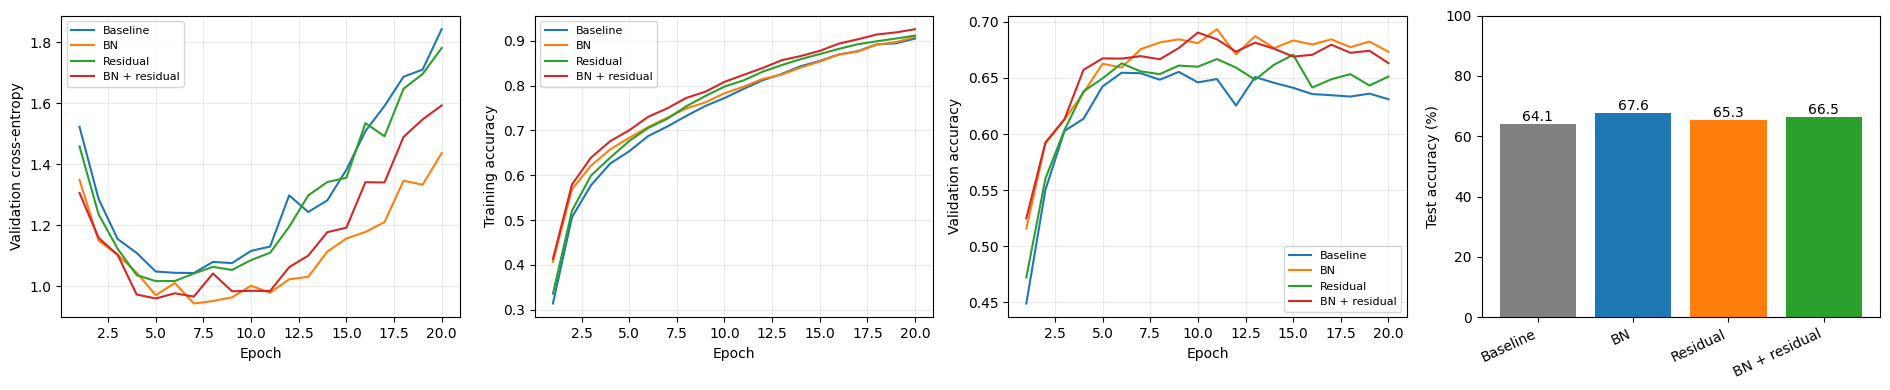

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(19, 4))

for name, record in records.items():
    h = record["history"]
    epochs = range(1, len(h["val_loss"]) + 1)
    axes[0].plot(epochs, h["val_loss"], label=name)
    axes[1].plot(epochs, h["train_acc"], label=name)
    axes[2].plot(epochs, h["val_acc"], label=name)

for ax, ylabel in zip(
    axes[:3],
    ["Validation cross-entropy", "Training accuracy", "Validation accuracy"],
):
    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)

names = list(records)
accs = [100 * records[name]["test_acc"] for name in names]
positions = range(len(names))

axes[3].bar(
    positions, accs,
    color=["gray", "tab:blue", "tab:orange", "tab:green"],
)
axes[3].set_xticks(positions, names, rotation=25, ha="right")
axes[3].set_ylim(0, 100)
axes[3].set_ylabel("Test accuracy (%)")

for i, value in enumerate(accs):
    axes[3].text(i, value + 1, f"{value:.1f}", ha="center")

plt.tight_layout()
plt.show()

### Compare predictions on the same images
All models read exactly the same test images. Green labels indicate correct predictions.

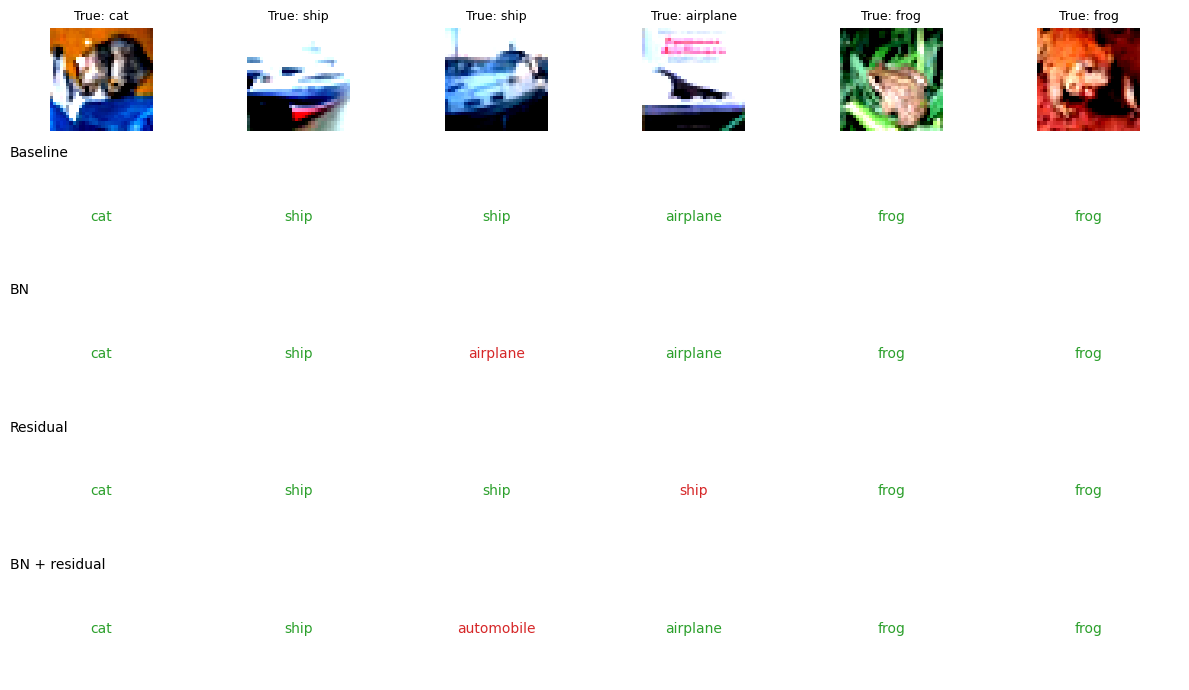

In [10]:
images, targets = next(iter(test_loader))
fig, axes = plt.subplots(5, 6, figsize=(12, 7))
for j in range(6):
    axes[0, j].imshow(image_for_display(images[j]))
    axes[0, j].set_title("True: " + classes[targets[j]], fontsize=9)
    axes[0, j].axis("off")
for row, (name, net) in enumerate(models.items(), start=1):
    net.eval()
    with torch.no_grad():
        predictions = net(images[:6]).argmax(1)
    for j in range(6):
        axes[row, j].text(0.5, 0.5, classes[predictions[j]], ha="center", va="center",
                          color="tab:green" if predictions[j] == targets[j] else "tab:red")
        axes[row, j].axis("off")
    axes[row, 0].set_title(name, loc="left", fontsize=10)
plt.tight_layout()
plt.show()

### Inspect one trained model's feature maps
Select a variant below. Show the convolution output, the activation after BN/shortcut when enabled, and the pooled result. Each panel has its own color scale.

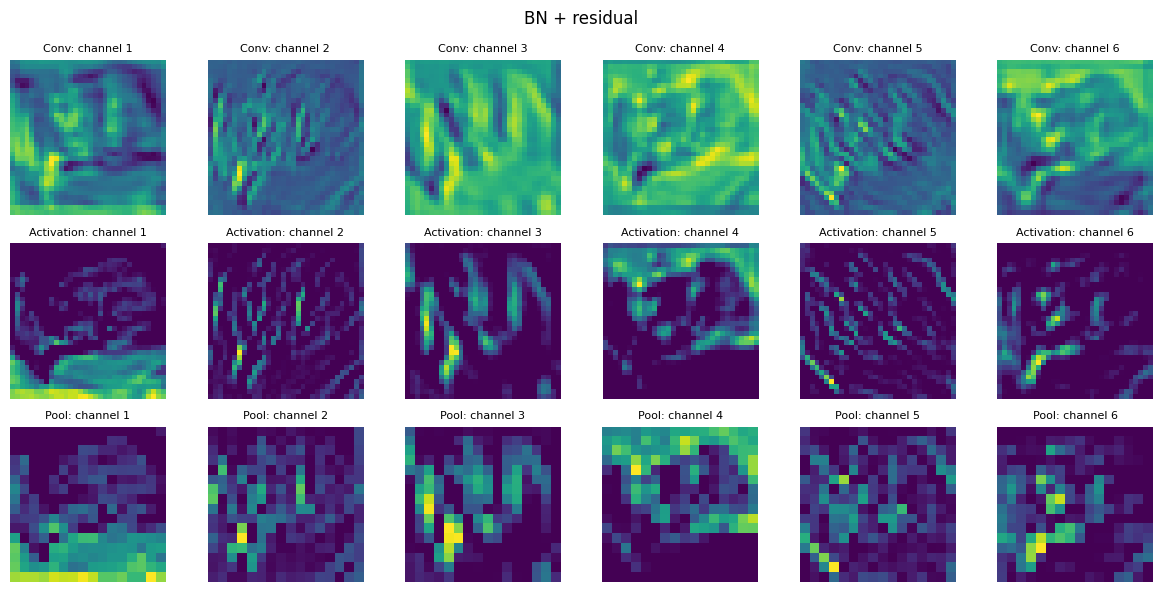

In [11]:
VIEW_MODEL = "BN + residual"
net = models[VIEW_MODEL].eval()
with torch.no_grad():
    x = images[:1]
    stage = net.stage1
    a = stage.conv(x)
    f = stage.bn(a)
    s = stage.shortcut(x) if stage.shortcut is not None else torch.zeros_like(f)
    h = torch.relu(f + s)
    p = stage.pool(h)
fig, axes = plt.subplots(3, 6, figsize=(12, 6))
for row, (label, tensor) in enumerate([("Conv", a), ("Activation", h), ("Pool", p)]):
    for c in range(6):
        axes[row, c].imshow(tensor[0, c], cmap="viridis")
        axes[row, c].set_title(f"{label}: channel {c+1}", fontsize=8)
        axes[row, c].axis("off")
plt.suptitle(VIEW_MODEL)
plt.tight_layout()
plt.show()

### Classroom workflow
1. Before class, train all four models once with `MODE = "train"` on your GPU.
2. Keep this notebook, the `cnn_checkpoints` folder, and cached `data` folder together. Distribute the checkpoint folder if students should skip training.
3. In class, set `MODE = "load"` and run the notebook. Weights, BN statistics, curves, and recorded metrics load from disk; prediction/feature-map cells only run inference.

Saved weights allow you to reproduce inference. Learning curves require the saved histories too, which is why both are stored in each checkpoint.

References: [CIFAR-10](https://www.cs.toronto.edu/~kriz/cifar.html), [PyTorch CIFAR-10 loader](https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.CIFAR10.html).